# 3. A legged robot on a battery: the price, a clock, and a reserve margin

A robot runs forward (MuJoCo's HalfCheetah) on a mission of 1000 steps. It now carries a battery: each step draws an
idle load plus the resistive losses of its motors, which grow with the square of the torques, scaled by an
efficiency that varies from mission to mission with battery health and temperature and is not observed. A robot
whose battery runs flat before the end of the mission is stranded.

Running fast earns the most per step and drains the battery fastest. This notebook shows:

1. how often a gait trained without a battery would be stranded;
2. what the policy must observe to pace a battery: the charge left and the time left;
3. what prices do to stranding and to distance covered;
4. a reserve margin (the interior barrier) against a battery that holds less than the robot believes;
5. validation and the report.

The trained policies come from the campaign in `campaigns/` (PPO, 2 million steps, three seeds per configuration).
Re-evaluating them needs Gymnasium with MuJoCo.

In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("..").resolve() / "campaigns"))
from records import Campaign
from bpg import Requirement, Stage, evaluate, interpret, plan
from bpg.problems.energy import Battery, make_robot_env

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
camp = Campaign("robot")
battery = Battery()
spec = battery.spec()

## 1. A gait trained without a battery

The energy a gait uses over a mission varies with the mission's efficiency. Against a battery of 2,500 units, a
gait trained without a battery would be stranded in most missions.

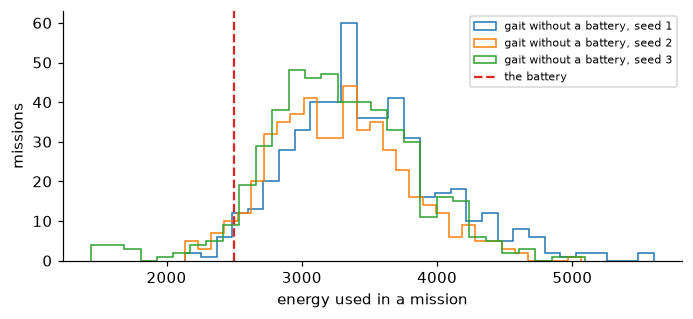

In [2]:
fig, ax = plt.subplots(figsize=(6.4, 3.0))
for s in camp.seeds("no-battery"):
    e = np.array(camp.record("no-battery", s)["evaluation"]["energy"])
    ax.hist(e, bins=30, histtype="step", label=f"gait without a battery, seed {s}")
ax.axvline(battery.charge, color="C3", ls="--", label="the battery")
ax.set_xlabel("energy used in a mission"); ax.set_ylabel("missions"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 2. The requirement, and what the policy must observe

The robot should be stranded in at most 5% of missions, shown at 95% confidence. The task's reward can be negative
(running backwards), so the stage prices only the failure (`clip_utility=False`).

The policy has to pace the battery, and pacing needs two inputs: how much charge is left and how much of the
mission is left. The task's own observation has no clock. The wrapper appends the remaining charge, and with
`observe_time=True` also the elapsed fraction of the mission. Without the clock the robot cannot tell whether its
charge will last.

In [3]:
req = Requirement(T=spec.horizon - 1, alpha=0.05, zeta=0.05, family=10)
print(Campaign.show(camp.table(["unpriced-no-clock", "unpriced", "price-3-no-clock", "price-3"], extras=("distance",)), extras=("distance",)))

configuration    seeds        failure (min-max)          utility (min-max)     distance
unpriced-no-clock     3  63.733% (52.60%-71.20%)           2758 (2624-2960)    [223.106]
unpriced             3  20.400% (17.60%-24.00%)           2717 (2637-2786)    [226.668]
price-3-no-clock     3  32.800% (13.40%-47.20%)           2482 (2033-2764)    [205.009]
price-3              3   10.400% (8.60%-13.40%)           2356 (1781-2688)    [196.803]


Without the clock, the robot is stranded in more than half of its missions when there is no price, and a price helps
only in some seeds. With the clock, stranding without a price falls to about a fifth. A policy that cannot see the
time left cannot pace a budget, however the failure is priced. With a fixed horizon, observe the time.

## 3. Prices

The campaign trained the robot, with the clock, at prices of 0, 1, 3 and 10 per step from the failure to the end of
the mission.

In [4]:
prices = ["unpriced", "price-1", "price-3", "price-10"]
print(Campaign.show(camp.table(prices, extras=("distance", "energy")), extras=("distance", "energy")))

configuration    seeds        failure (min-max)          utility (min-max)     distance       energy
unpriced             3  20.400% (17.60%-24.00%)           2717 (2637-2786)    [226.668]   [2212.145]
price-1              3  16.800% (16.00%-17.60%)           2432 (1824-2779)    [204.585]   [2185.089]
price-3              3   10.400% (8.60%-13.40%)           2356 (1781-2688)    [196.803]   [2093.093]
price-10             3     0.467% (0.00%-1.40%)           1957 (1560-2162)    [163.733]   [1691.245]


Stranding falls steadily with the price, and so does the distance covered: pacing the battery means running slower.
Only the price of 10 meets the 5% tolerance in every seed. The price chooses how much distance to give up for a lower
risk; the tolerance decides which price is enough.

## 4. A reserve margin against a weaker battery

Every configuration was also evaluated with a battery that holds 10% less than the robot believes (the robot still
sees the nominal charge). A price on failure alone leaves no reserve; the interior barrier charges a small amount
every step that grows as the charge falls.

In [5]:
rows = []
for cfg in ["unpriced", "price-1", "price-3", "price-10", "barrier"]:
    nominal = [np.mean(r["evaluation"]["failed"]) for r in camp.records(cfg)]
    weak = [np.mean(r["extra_evaluations"][0]["episodes"]["failed"]) for r in camp.records(cfg)]
    dist = [np.mean(r["evaluation"]["distance"]) for r in camp.records(cfg)]
    print(f"{cfg:10s} stranded: nominal battery {np.mean(nominal):6.1%}, battery 10% weaker {np.mean(weak):6.1%};  distance {np.mean(dist):6.0f}")

unpriced   stranded: nominal battery  20.4%, battery 10% weaker  49.3%;  distance    227
price-1    stranded: nominal battery  16.8%, battery 10% weaker  45.3%;  distance    205
price-3    stranded: nominal battery  10.4%, battery 10% weaker  30.7%;  distance    197
price-10   stranded: nominal battery   0.5%, battery 10% weaker   2.1%;  distance    164


barrier    stranded: nominal battery   7.1%, battery 10% weaker  20.2%;  distance    168


With a battery that holds 10% less, every policy is stranded more often. A policy that meets the tolerance with room
to spare (the price of 10) keeps a margin under the weaker battery as well. The interior barrier at a lower price (3)
lowered stranding in two of three seeds, under both batteries, but its results varied widely across seeds; on this
problem a higher price was the more reliable way to a reserve. If the size of a possible battery error is known,
planning with the smaller battery is the cheaper margin.

## 5. Validate and report

We validate the candidate with the least stranding on its first evaluation, on 500 fresh missions, as a stochastic
policy and as its mean action. Ten candidates were inspected, so the error is shared among ten.

In [6]:
cands = [(c, s) for c in prices + ["barrier"] for s in camp.seeds(c)]
best = min(cands, key=lambda cs: np.mean(camp.record(*cs)["evaluation"]["failed"]))
print("candidate:", best, camp.record(*best)["note"])
stage = camp.stage(*best)
for det in (False, True):
    e = evaluate(lambda: make_robot_env(stage, battery), camp.policy(*best, deterministic=det), 500, spec=spec, stage=stage,
                 T=req.T, seed=555)
    name = f"the {'mean action of the' if det else 'stochastic'} policy {best[0]}, seed {best[1]}"
    print()
    print(interpret(spec, req, stage, e, candidate_name=name).summary(resource="charge", period="steps"))

candidate: ('price-10', 2) battery, price 10



The stochastic policy price-10, seed 2 was run on 500 fresh episodes. It ran out of charge within 1000 steps in 0 of them (0.00%).
With confidence 0.95, its probability of running out within 1000 steps is at most 1.054% (the error 0.05 is shared among 10 candidates).
Requirement (at most 5.00%): met.
Utility per episode: 1564 (standard error 3.7).
Episodes that came within 5% of running out, or ran out: 0.4%.

What this test does not show:
  - that the policy is the best possible at this risk: how far training fell short of the optimum is not measured;
  - its risk over more than 1000 steps, or that of other policies (its mean action, a retrained network);
  - its behavior outside the simulator.
Every bound with its assumptions: report.text().



The mean action of the policy price-10, seed 2 was run on 500 fresh episodes. It ran out of charge within 1000 steps in 0 of them (0.00%).
With confidence 0.95, its probability of running out within 1000 steps is at most 1.054% (the error 0.05 is shared among 10 candidates).
Requirement (at most 5.00%): met.
Utility per episode: 1903 (standard error 1.2).
Episodes that came within 5% of running out, or ran out: 0.0%.

What this test does not show:
  - that the policy is the best possible at this risk: how far training fell short of the optimum is not measured;
  - its risk over more than 1000 steps, or that of other policies (its mean action, a retrained network);
  - its behavior outside the simulator.
Every bound with its assumptions: report.text().


Both pass. The mean action covers more distance with no more stranding: it spends no effort on the noise that the
stochastic policy adds to its actions. If you deploy the mean action, it is the candidate whose validation counts.

## Train it yourself

```bash
python campaigns/run.py robot price-3 --seed 4       # about 5 minutes on one core
```